# TP M2-1 — Du signal brut à la fréquence cardiaque (PPG)

**Module 2 — vendredi 9 octobre 2026 — 10:00-12:30** (pause 10:45-11:00)
MBA Santé, IA & IoT — Epitech — Nicolas LAURIO
Énoncé complet : `TP_M2_1_Signal_PPG.md`

> Données : PhysioNet *BIDMC PPG and Respiration Dataset* v1.0.0 (licence ODC-BY 1.0 : on peut les utiliser en citant la source, voir la référence en fin de notebook). Le notebook les télécharge. Si le téléchargement échoue, il passe sur un signal **synthétique** (fabriqué par programme, il ne vient d'aucune personne). Usage **pédagogique** uniquement : ces calculs ne sont pas validés en médecine et ne servent à aucun diagnostic.

**Mode d'emploi**
- Vous n'écrivez pas de code. Exécutez les cellules **dans l'ordre** (Maj + Entrée). Le notebook marche de bout en bout sans rien changer.
- ▶ **Exécutez** : la cellule suivante se lance telle quelle.
- ✏️ **À vous** : la cellule suivante contient un réglage à changer. Dans Colab, c'est un **curseur** ; en local, changez seulement le nombre.
- Après un changement, relancez la cellule **et les suivantes** (Colab : menu *Exécution → Exécuter les cellules suivantes* ; Jupyter : *Run → Run Selected Cell and All Below*).
- Les **questions** sont en gras. Répondez dans la cellule « Vos réponses » juste en dessous (double-clic pour écrire, Maj + Entrée pour valider).

### Rappel en 5 lignes
1. **PPG** (photopléthysmographie) : la mesure du pouls par la lumière. Une petite lampe (LED) éclaire la peau, un capteur de lumière mesure ce qui revient. À chaque battement, il y a un peu plus de sang sous la peau : on obtient **une vague par battement**.
2. **Échantillonnage** : le capteur prend une mesure à intervalle régulier. Ici, **125 mesures par seconde** (fs = 125 Hz ; « Hz » veut dire « fois par seconde »), soit une mesure toutes les 8 ms. Pour connaître le temps, on divise le numéro de la mesure par 125 : la mesure n° 250 tombe à 250 ÷ 125 = 2 s.
3. **Passer des Hz aux bpm** (battements par minute) : on multiplie par 60. Un battement par seconde (1 Hz) = 60 bpm. Donc 40 à 180 bpm correspondent à 0,67 à 3 Hz.
4. Le signal brut contient aussi autre chose que le pouls : une **dérive lente** (respiration, posture : moins de 0,5 fois par seconde), un **bruit rapide** (plus de 5 fois par seconde) et des **artefacts de mouvement**, qui vont souvent à la même vitesse que le pouls.
5. **Filtrer**, c'est garder seulement les variations à la vitesse du pouls, pour mieux repérer les battements. Ce que le filtre ne peut pas enlever, un **indice de qualité** (une note de confiance) doit le signaler.

## Étape 0 — Votre numéro d'équipe

Chaque équipe analyse un patient différent : équipe 1 → `bidmc_01`, équipe 2 → `bidmc_02`… On comparera les résultats en plénière.

✏️ **À vous : changez seulement le numéro `EQUIPE`, puis exécutez la cellule.** Laissez `FORCER_SYNTHETIQUE = False` (sauf consigne de l'intervenant ou si le téléchargement échoue).

In [1]:
#@title À vous : numéro d'équipe
EQUIPE = 5  #@param {type:"integer"}
FORCER_SYNTHETIQUE = False  #@param {type:"boolean"}
# FORCER_SYNTHETIQUE = True : utiliser le PPG synthétique même si le réseau fonctionne (test du repli)

▶ **Pas besoin de lire ce code : exécutez la cellule suivante sans la modifier.**

Elle prépare les outils (téléchargement, calculs, données de secours). Elle affiche seulement « Boîte à outils prête » et le numéro de votre enregistrement.

In [2]:
# ===== Boîte à outils : exécutez cette cellule sans la modifier =====
import json
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import signal

plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["axes.grid"] = True

FS = 125            # fréquence d'échantillonnage de BIDMC : 125 mesures par seconde
FENETRE_S = 8.0     # une FC est calculée sur une fenêtre glissante de 8 s
URL_BIDMC = "https://physionet.org/files/bidmc/1.0.0/bidmc_csv/"
RECORD = f"{(EQUIPE - 1) % 53 + 1:02d}"   # équipe 1 -> "01", équipe 2 -> "02"... (53 enregistrements)


def trouver_ou_telecharger(nom):
    """Cherche le fichier à côté du notebook ou dans data/, sinon le télécharge depuis PhysioNet."""
    for dossier in (Path("."), Path("data")):
        if (dossier / nom).exists():
            return dossier / nom
    Path("data").mkdir(exist_ok=True)
    duree = "environ 3 Mo, de 30 s à 2 min" if "Signals" in nom else "quelques secondes"
    print(f"Téléchargement de {nom} depuis PhysioNet ({duree})...", flush=True)
    debut = time.time()
    with urllib.request.urlopen(URL_BIDMC + nom, timeout=60) as reponse:
        contenu = reponse.read()
    (Path("data") / nom).write_bytes(contenu)   # écrit seulement si le téléchargement est complet
    print(f"  terminé : {len(contenu) / 1e6:.1f} Mo en {time.time() - debut:.0f} s")
    return Path("data") / nom


def generer_ppg_synthetique(graine=1, duree_s=480, fs=FS):
    """PPG synthétique réaliste au format BIDMC (repli si pas de réseau). La FC « vraie » est connue."""
    rng = np.random.default_rng(graine)
    fc_moy = 62 + (graine * 11) % 40                     # chaque équipe a une FC moyenne différente
    t = np.arange(0, duree_s, 1 / fs)
    ppg = np.zeros_like(t)
    t_batt, fc_batt = [], []
    tb = 0.3
    while tb < duree_s:
        fc_i = fc_moy + 6 * np.sin(2 * np.pi * tb / 150) + 2 * np.sin(2 * np.pi * tb / 4) + rng.normal(0, 1)
        ibi = 60 / fc_i                                   # intervalle entre battements (s)
        i0, i1 = int(tb * fs), min(len(t), int((tb + 1.5) * fs))
        tt = t[i0:i1] - tb
        k = ibi / 0.8                                     # la forme d'onde s'adapte à la FC
        ppg[i0:i1] += (1 + rng.normal(0, 0.05)) * (
            np.exp(-((tt - 0.18 * k) ** 2) / (2 * (0.07 * k) ** 2))            # onde systolique
            + 0.45 * np.exp(-((tt - 0.42 * k) ** 2) / (2 * (0.10 * k) ** 2)))  # onde diastolique
        t_batt.append(tb)
        fc_batt.append(fc_i)
        tb += ibi
    ppg *= 1 + 0.10 * np.sin(2 * np.pi * 0.25 * t)         # respiration (15 /min) : amplitude
    ppg += 0.25 * np.sin(2 * np.pi * 0.25 * t + 0.5)       # respiration : ligne de base
    ppg += 0.30 * np.sin(2 * np.pi * 0.03 * t)             # dérive lente (posture, température)
    ppg += rng.normal(0, 0.03, len(t))                     # bruit électronique
    ppg = (ppg - ppg.min()) / (ppg.max() - ppg.min())      # normalisé entre 0 et 1 comme BIDMC
    secondes = np.arange(0, duree_s + 1)
    hr = np.round(np.interp(secondes, t_batt, fc_batt))
    signals = pd.DataFrame({"Time [s]": np.round(t, 3), "PLETH": ppg})
    numerics = pd.DataFrame({"Time [s]": secondes, "HR": hr, "PULSE": hr})
    return signals, numerics


def charger_enregistrement(record, forcer_synthetique=False, repli=True):
    """Renvoie (signals, numerics, source). Bascule sur le PPG synthétique en cas d'échec."""
    if not forcer_synthetique:
        try:
            sig = pd.read_csv(trouver_ou_telecharger(f"bidmc_{record}_Signals.csv"))
            num = pd.read_csv(trouver_ou_telecharger(f"bidmc_{record}_Numerics.csv"))
            sig.columns = sig.columns.str.strip()   # les noms commencent par une espace : " PLETH"
            num.columns = num.columns.str.strip()   # idem : " HR"
            if "PLETH" not in sig.columns or "HR" not in num.columns or len(sig) < 60 * FS:
                raise ValueError("fichier incomplet ou colonnes inattendues")
            return sig, num, f"BIDMC enregistrement {record}"
        except Exception as erreur:
            if not repli:
                raise
            print(f"Données BIDMC indisponibles : {erreur!r}")
    print("=" * 72)
    print("ATTENTION : données SYNTHÉTIQUES (repli). Signalez-le dans votre synthèse.")
    print("=" * 72)
    sig, num = generer_ppg_synthetique(graine=int(record))
    return sig, num, f"PPG synthétique (repli, graine {record})"


def reference_fc(numerics, t):
    """FC de référence du moniteur (colonne HR, une valeur par seconde), sans les bords."""
    ref = numerics[["Time [s]", "HR"]].dropna()
    garde = (ref["Time [s]"] >= FENETRE_S / 2) & (ref["Time [s]"] <= t[-1] - FENETRE_S / 2)
    return ref.loc[garde, "Time [s]"].to_numpy(float), ref.loc[garde, "HR"].to_numpy(float)


def fc_par_fenetre(t_pics, instants, fenetre=FENETRE_S):
    """Pour chaque instant : FC (médiane des intervalles) et irrégularité (CV) sur une fenêtre centrée."""
    ibi = np.diff(t_pics)            # intervalles entre battements (s)
    t_ibi = t_pics[1:]
    fc = np.full(len(instants), np.nan)
    cv = np.full(len(instants), np.nan)
    for k, tc in enumerate(instants):
        dans = (t_ibi >= tc - fenetre / 2) & (t_ibi < tc + fenetre / 2)
        if dans.sum() >= 3:          # au moins 3 intervalles pour calculer quelque chose
            fc[k] = 60 / np.median(ibi[dans])
            cv[k] = np.std(ibi[dans]) / np.mean(ibi[dans])   # coefficient de variation
    return fc, cv


def mae(fc_estimee, fc_reference, masque=None):
    """Erreur absolue moyenne (bpm), calculée là où une FC est disponible (et dans le masque)."""
    ok = ~np.isnan(fc_estimee)
    if masque is not None:
        ok &= masque
    return float(np.mean(np.abs(fc_estimee[ok] - fc_reference[ok]))) if ok.any() else float("nan")


def ajouter_artefact(x, t, debut, duree, gain, graine=0):
    """Simule un mouvement : bruit dans la bande 1-3 Hz (comme une marche) + sauts de ligne de base."""
    rng = np.random.default_rng(graine)
    y = x.copy()
    zone = (t >= debut) & (t < debut + duree)
    bruit = signal.sosfilt(signal.butter(2, [1, 3], btype="bandpass", fs=FS, output="sos"),
                           rng.normal(0, 1, zone.sum()))
    bruit = gain * np.std(x) * bruit / np.std(bruit)
    sauts = np.cumsum(rng.normal(0, 0.02, zone.sum())) * np.std(x)
    y[zone] += bruit + sauts
    return y


print(f"Boîte à outils prête. Équipe {EQUIPE} -> enregistrement bidmc_{RECORD}.")

Boîte à outils prête. Équipe 5 -> enregistrement bidmc_05.


## Étape 1 — Charger l'enregistrement

Le notebook cherche les fichiers `bidmc_XX_Signals.csv` et `bidmc_XX_Numerics.csv` à côté du notebook (ou dans `data/`). Sinon, il les télécharge depuis PhysioNet. **Patientez** : cela prend de 30 s à 2 min. En cas d'échec, il passe sur des données synthétiques et l'affiche en gros.

- `Signals` : les signaux, 125 mesures par seconde. La colonne **`PLETH`** est le signal du capteur de pouls (le PPG).
- `Numerics` : les valeurs du moniteur, une par seconde. **`HR`** est la FC du moniteur : c'est notre **référence**, la valeur considérée comme juste.

▶ **Exécutez la cellule suivante.**

**Vous devez voir** : `Source : BIDMC enregistrement XX`, 60001 échantillons (mesures), une durée de 480 s.

In [3]:
signals, numerics, SOURCE = charger_enregistrement(RECORD, FORCER_SYNTHETIQUE)

ppg_brut = signals["PLETH"].to_numpy(dtype=float)
t = np.arange(len(ppg_brut)) / FS     # temps (s) = numéro d'échantillon / fréquence d'échantillonnage

print("Source :", SOURCE)
print("Colonnes Signals  :", list(signals.columns))
print("Colonnes Numerics :", list(numerics.columns))
print(f"{len(ppg_brut)} échantillons à {FS} Hz -> durée {t[-1]:.0f} s ({t[-1] / 60:.0f} min)")
print(f"FC de référence (HR) : moyenne {numerics['HR'].mean():.0f} bpm, "
      f"de {numerics['HR'].min():.0f} à {numerics['HR'].max():.0f} bpm")
numerics.head()

Source : BIDMC enregistrement 05
Colonnes Signals  : ['Time [s]', 'RESP', 'PLETH', 'II', 'V', 'AVR']
Colonnes Numerics : ['Time [s]', 'HR', 'PULSE', 'RESP', 'SpO2']
60001 échantillons à 125 Hz -> durée 480 s (8 min)
FC de référence (HR) : moyenne 98 bpm, de 96 à 101 bpm


,Time [s],HR,PULSE,RESP,SpO2
0,0,98,98.0,10,99.0
1,1,98,98.0,10,99.0
2,2,98,97.0,10,99.0
3,3,98,97.0,10,99.0
4,4,98,97.0,10,99.0


**Question 1.** Combien de mesures (échantillons) contient l'enregistrement ? Vérifiez avec un calcul : 480 secondes × 125 mesures par seconde = ? Combien de millisecondes séparent deux mesures (1 000 ÷ 125) ?

*Vos réponses :*

L'enregistrement contient **60 001 échantillons**. Le calcul : 480 s × 125 mesures/s = **60 000**, et on obtient 60 001 parce que l'enregistrement va de l'instant 0 à l'instant 480 s **inclus** (bornes comprises, comme une règle de 480 cm qui porte 481 graduations).

Deux mesures sont séparées de 1 000 ÷ 125 = **8 ms**.

Source : BIDMC enregistrement 05 (téléchargé depuis PhysioNet, pas de repli synthétique). FC de référence : 98,2 bpm en moyenne, de 96 à 101 bpm.

## Étape 2 — Regarder 10 secondes de signal brut

Le signal « brut », c'est le signal tel qu'il sort du capteur, pas encore traité.

✏️ **À vous** : `DEBUT_ZOOM` choisit les 10 secondes affichées (par défaut de 60 à 70 s). Exécutez la cellule, puis comptez les battements **avant** de lire la FC de référence affichée dessous.

**Vous devez voir** : une « vague » par battement, souvent suivie d'une petite bosse (l'onde diastolique, un rebond normal du pouls), le tout posé sur une ondulation plus lente.

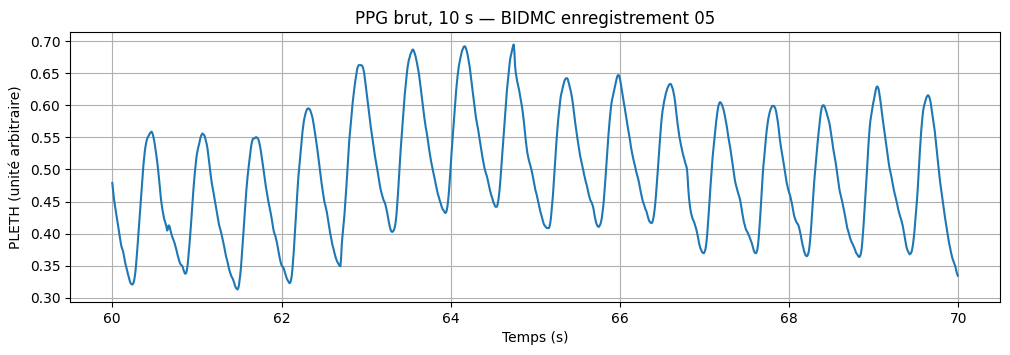

(À regarder APRÈS avoir compté) FC de référence sur ces 10 s : 98 bpm


In [4]:
#@title À vous : début de la fenêtre de 10 s
DEBUT_ZOOM = 60  #@param {type:"slider", min:0, max:460, step:10}

zoom = (t >= DEBUT_ZOOM) & (t < DEBUT_ZOOM + 10)
plt.plot(t[zoom], ppg_brut[zoom])
plt.title(f"PPG brut, 10 s — {SOURCE}")
plt.xlabel("Temps (s)")
plt.ylabel("PLETH (unité arbitraire)")
plt.show()

hr_zoom = numerics.loc[(numerics["Time [s]"] >= DEBUT_ZOOM) & (numerics["Time [s]"] < DEBUT_ZOOM + 10), "HR"]
print(f"(À regarder APRÈS avoir compté) FC de référence sur ces 10 s : {hr_zoom.mean():.0f} bpm")

**Question 2.** Comptez les battements sur ces 10 s, puis multipliez par 6 pour avoir des bpm (10 s = un sixième de minute ; exemple : 12 battements → 72 bpm). Êtes-vous proches de la FC de référence affichée sous le graphique (regardez-la **après** avoir compté) ?

*Vos réponses :*

Sur la fenêtre 60-70 s, nous comptons **16 vagues** (une par battement, chacune suivie de sa petite bosse diastolique). 16 × 6 = **96 bpm**.

La FC de référence affichée sous le graphique est de **98 bpm** (97,6 bpm avant arrondi) : nous sommes à **2 bpm près**, soit environ 2 % d'écart. Le comptage à l'œil suffit donc à retrouver l'ordre de grandeur — l'erreur vient surtout du battement « coupé » aux deux bords de la fenêtre.

## Étape 3 — Nettoyer le signal avec un filtre

Le **filtre passe-bande** marche comme un tamis : il garde seulement les variations dont la vitesse est comprise entre `F_BAS` et `F_HAUT` (en fois par seconde, Hz). Il enlève l'ondulation lente et le bruit rapide. `ORDRE` règle la netteté de la coupure.

Le troisième graphique s'appelle le **spectre**. Il montre, de gauche (lent) à droite (rapide), à quelles vitesses le signal brut varie le plus. Zone verte = ce que le filtre garde. Trait rouge = la FC de référence.

✏️ **À vous** :
1. Exécutez d'abord avec le réglage par défaut (**0,5-5 Hz**).
2. Mettez `F_HAUT` à 1 (**0,5-1 Hz**, trop étroit), relancez cette cellule et les suivantes, et comparez.
3. **Revenez à 0,5-5 Hz** : ce réglage sert pour toute la suite.

**Vous devez voir** (0,5-5 Hz) : un signal centré sur 0, sans ondulation lente, avec des pics nets ; le trait rouge dans la zone verte.

*Détail technique (facultatif) : `fs=FS` dit à SciPy que 0,5 et 5 sont des hertz ; `sosfiltfilt` filtre dans un sens puis dans l'autre, donc les pics restent à leur place.*

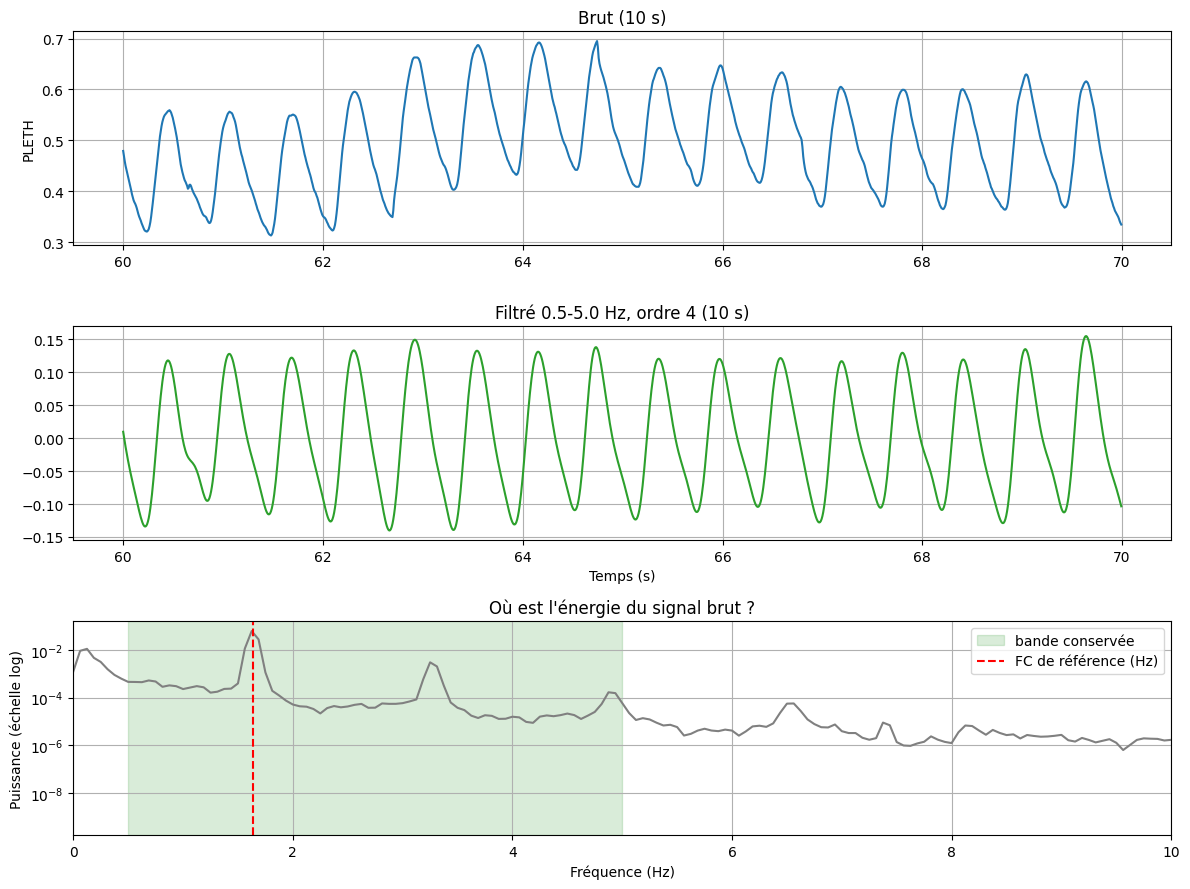

In [5]:
#@title À vous : réglage du filtre { run: "auto" }
F_BAS = 0.5  #@param {type:"slider", min:0.1, max:3, step:0.1}
F_HAUT = 5.0  #@param {type:"slider", min:1, max:20, step:0.5}
ORDRE = 4  #@param {type:"slider", min:1, max:8, step:1}

if F_BAS >= F_HAUT:
    raise ValueError("F_BAS doit être strictement inférieure à F_HAUT : corrigez le réglage.")

sos = signal.butter(ORDRE, [F_BAS, F_HAUT], btype="bandpass", fs=FS, output="sos")  # le filtre
ppg_filtre = signal.sosfiltfilt(sos, ppg_brut)                                      # aller-retour

fig, axes = plt.subplots(3, 1, figsize=(12, 9))
axes[0].plot(t[zoom], ppg_brut[zoom])
axes[0].set(title="Brut (10 s)", ylabel="PLETH")
axes[1].plot(t[zoom], ppg_filtre[zoom], color="tab:green")
axes[1].set(title=f"Filtré {F_BAS}-{F_HAUT} Hz, ordre {ORDRE} (10 s)", xlabel="Temps (s)")
f, dsp = signal.welch(ppg_brut - ppg_brut.mean(), fs=FS, nperseg=16 * FS)
axes[2].semilogy(f, dsp, color="gray")
axes[2].axvspan(F_BAS, F_HAUT, color="green", alpha=0.15, label="bande conservée")
axes[2].axvline(numerics["HR"].mean() / 60, color="red", ls="--", label="FC de référence (Hz)")
axes[2].set(xlim=(0, 10), title="Où est l'énergie du signal brut ?", xlabel="Fréquence (Hz)",
            ylabel="Puissance (échelle log)")
axes[2].legend()
plt.tight_layout()
plt.show()

**Question 3.** Convertissez 0,5 Hz et 5 Hz en bpm (on multiplie par 60 ; exemple : 2 Hz × 60 = 120 bpm). Pourquoi garder cette bande, en une phrase ? Avec 0,5-1 Hz, que devient la courbe, et pourquoi ? (Aide : sur le spectre, le trait rouge est-il encore dans la zone verte ?)

*Repère horaire : vers 10:45, vous devriez avoir terminé cette étape (pause 10:45-11:00).*

*Vos réponses :*

**Conversion.** 0,5 Hz × 60 = **30 bpm** ; 5 Hz × 60 = **300 bpm**.

**Pourquoi cette bande.** Elle contient toutes les fréquences cardiaques physiologiquement possibles (30 à 300 bpm, donc largement les 40-180 bpm attendus), tout en coupant ce qui n'est pas le pouls : en dessous de 0,5 Hz la dérive lente (respiration à ~0,25 Hz, posture, température), au-dessus de 5 Hz le bruit électronique.

**Avec 0,5-1 Hz.** Cette bande ne garde que 30 à 60 bpm. Or notre patient est à 98 bpm, soit 98 ÷ 60 = **1,64 Hz** : sur le spectre, le trait rouge est **en dehors de la zone verte**. Le filtre supprime donc le pouls lui-même et ne laisse qu'une ondulation lente très atténuée. Conséquence mesurée : **289 pics détectés au lieu de 766**, et la MAE passe de **1,84 à 58,70 bpm**. Leçon : une bande « plus propre » qui exclut le signal utile est pire que pas de filtre du tout.

Nous revenons à **0,5-5 Hz, ordre 4** pour toute la suite.

## Étape 4 — Repérer les battements (les pics)

Le notebook cherche les sommets de la courbe filtrée, avec deux garde-fous :
- **`FC_MAX`** fixe le temps minimum entre deux pics. En mots : 60 secondes divisées par la FC la plus haute possible. Exemple : 60 ÷ 180 = 0,33 s, soit 0,33 × 125 ≈ 41 mesures.
- **`PROEMINENCE`** fixe la hauteur minimale d'un pic, pour ignorer la petite bosse qui suit chaque battement (et le bruit).

✏️ **À vous** :
1. Exécutez avec le réglage par défaut et notez le nombre de battements.
2. Testez `FC_MAX` = 60, notez.
3. Testez `FC_MAX` = 300 avec `PROEMINENCE` = 0, notez.
4. **Revenez à 180 et 0,5.**

**Vous devez voir** (réglage par défaut) : un triangle rouge sur chaque grand pic, aucun sur la petite bosse qui suit.

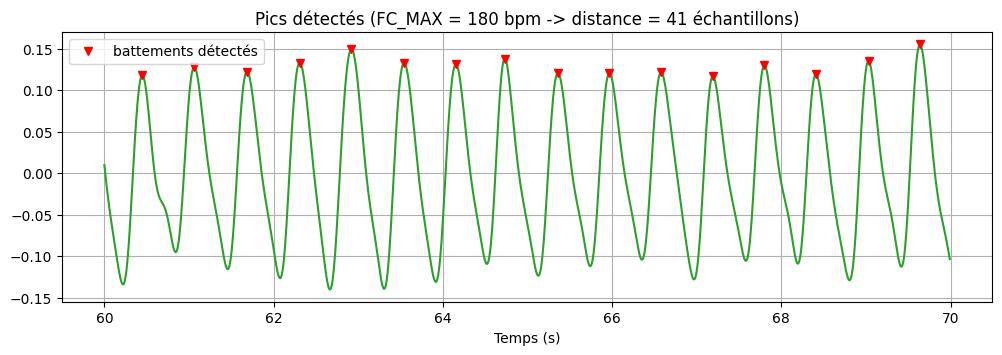

16 battements sur les 10 s affichées, 766 sur l'enregistrement complet


In [6]:
#@title À vous : réglage de la détection { run: "auto" }
FC_MAX = 180  #@param {type:"slider", min:40, max:300, step:10}
PROEMINENCE = 0.5  #@param {type:"slider", min:0, max:2, step:0.1}

distance_min = int(FS * 60 / FC_MAX)     # écart minimal entre deux pics, en échantillons
pics, _ = signal.find_peaks(ppg_filtre, distance=distance_min,
                            prominence=PROEMINENCE * np.std(ppg_filtre))
t_pics = t[pics]                         # instants des battements (s)

dans_zoom = (t_pics >= DEBUT_ZOOM) & (t_pics < DEBUT_ZOOM + 10)
plt.plot(t[zoom], ppg_filtre[zoom], color="tab:green")
plt.plot(t_pics[dans_zoom], ppg_filtre[pics][dans_zoom], "rv", label="battements détectés")
plt.title(f"Pics détectés (FC_MAX = {FC_MAX} bpm -> distance = {distance_min} échantillons)")
plt.xlabel("Temps (s)")
plt.legend()
plt.show()
print(f"{dans_zoom.sum()} battements sur les 10 s affichées, {len(pics)} sur l'enregistrement complet")

**Question 4.** Notez le nombre de battements détectés sur tout l'enregistrement avec `FC_MAX` = 60, puis avec `FC_MAX` = 300 et `PROEMINENCE` = 0. Dans chaque cas : trop peu ou trop de battements ? Pourquoi, en une phrase ? Quel réglage gardez-vous ?

*Vos réponses :*

| Réglage | Battements détectés (480 s) | Attendu (~98 bpm → ~785) | Verdict | MAE |
| --- | --- | --- | --- | --- |
| FC_MAX 180, PROEMINENCE 0,5 (défaut) | **766** | ~785 | correct | 1,84 bpm |
| FC_MAX 60 | **337** | ~785 | **trop peu** | 53,17 bpm |
| FC_MAX 300 + PROEMINENCE 0 | **792** | ~785 | **trop** | 1,70 bpm |

**FC_MAX = 60** impose un écart minimal de 60 ÷ 60 = 1 s (125 échantillons) entre deux pics. Notre patient bat toutes les 0,61 s : on s'interdit donc presque un battement sur deux, d'où 337 détections et une FC estimée autour de 50 bpm (MAE 53 bpm).

**FC_MAX = 300 avec PROEMINENCE = 0** autorise un pic tous les 0,2 s (25 échantillons) sans aucune hauteur minimale : on attrape en plus l'onde diastolique et des bosses de bruit, d'où 792 détections. La MAE reste basse (1,70 bpm) **uniquement** parce que l'étape 6 prend la *médiane* des intervalles sur 8 s, qui encaisse quelques faux pics — mais la FC instantanée, elle, devient bruitée. On ne garde pas un réglage dont la justesse dépend d'un filet de sécurité en aval.

**Réglage retenu : FC_MAX = 180 et PROEMINENCE = 0,5.** 180 bpm est la limite physiologique haute au repos, et la proéminence à 0,5 écart-type écarte la bosse diastolique sans rater de vrai battement (16 détections sur les 10 s affichées, soit exactement ce qu'on compte à l'œil).

## Étape 5 — Calculer la FC

- Le **temps entre deux battements** (IBI dans le code) se mesure en secondes, d'un pic au suivant.
- **FC instantanée** : on divise 60 par ce temps. Exemple : 0,8 s → 60 ÷ 0,8 = 75 bpm. Une valeur par battement.
- **FC moyenne** : on divise 60 par la moyenne de ces temps. Exemple : 0,66 s → 60 ÷ 0,66 ≈ 91 bpm.

▶ **Exécutez la cellule suivante.**

**Vous devez voir** : un nuage de points assez plat autour de la FC moyenne, avec parfois quelques points isolés très hauts ou très bas. Notez l'instant (en secondes) de ces points.

FC moyenne estimée : 95.8 bpm (référence HR moyenne : 98.2 bpm)
FC instantanée : min 10, médiane 99, max 129 bpm


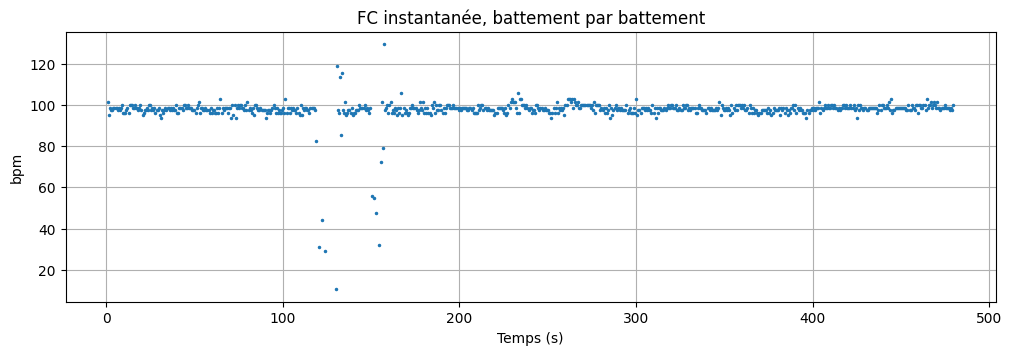

In [7]:
ibi = np.diff(t_pics)        # intervalles entre battements (s)
fc_inst = 60 / ibi           # FC instantanée (bpm), une valeur par battement
fc_moyenne = 60 / np.mean(ibi)

print(f"FC moyenne estimée : {fc_moyenne:.1f} bpm (référence HR moyenne : {numerics['HR'].mean():.1f} bpm)")
print(f"FC instantanée : min {fc_inst.min():.0f}, médiane {np.median(fc_inst):.0f}, max {fc_inst.max():.0f} bpm")

plt.plot(t_pics[1:], fc_inst, ".", ms=3)
plt.title("FC instantanée, battement par battement")
plt.xlabel("Temps (s)")
plt.ylabel("bpm")
plt.show()

**Question 5.** Votre FC moyenne est-elle proche de la référence (oui / non, écart en bpm) ? Voyez-vous des points très bas ou très hauts (moins de 40 ou plus de 180 bpm) ? Si oui, zoomez sur l'un d'eux (étape 2, curseur `DEBUT_ZOOM`) : que voyez-vous sur la courbe ?

*Vos réponses :*

**FC moyenne estimée : 95,8 bpm** contre **98,2 bpm** de référence → écart de **2,4 bpm**. Oui, c'est proche (2,4 %).

**Points aberrants : oui.** La FC instantanée descend à **10 bpm** et monte à **129 bpm** (médiane 99 bpm). Quatre battements sortent de la plage 40-180 bpm, à **120,8 s, 124,2 s, 129,9 s et 154,7 s**.

**Zoom (DEBUT_ZOOM = 120 puis 150).** Ce n'est pas le cœur : le signal **n'a plus la forme d'un pouls**. Entre 119 et 130 s il devient plat par paliers (34 % des échantillons consécutifs sont strictement identiques — le capteur renvoie une valeur figée), et vers 150-152 s il sature brutalement (il touche 1,0 puis retombe à 0,0, les bornes de l'échelle PLETH). C'est un **décrochage du capteur** : sonde déplacée sur le doigt, ou recalibration de l'oxymètre. Preuve : pendant ces secondes, la FC du moniteur — calculée sur l'**ECG**, un autre capteur — reste tranquillement à 98 bpm. Le cœur va bien, c'est la mesure optique qui est perdue.

C'est exactement le genre d'événement que l'indice de qualité de l'étape 8 doit intercepter.

## Étape 6 — Comparer à la FC du moniteur

Le moniteur donne une FC par seconde. Le notebook calcule aussi une FC par seconde, sur les 8 secondes autour : c'est une **fenêtre glissante**, comme une loupe qu'on fait avancer. Il prend la **médiane** des temps entre battements (la valeur du milieu), pour qu'un battement raté compte peu.

L'**erreur moyenne** (MAE dans le code) dit de combien de bpm on se trompe, en moyenne. Chaque seconde, on prend l'écart entre notre FC et celle du moniteur, sans le signe, puis on fait la moyenne. Exemple : écarts de 1, 3 et 2 bpm → (1 + 3 + 2) ÷ 3 = 2 bpm. Le notebook la calcule aussi **sans filtre**, pour voir ce que le filtre apporte.

▶ **Exécutez la cellule suivante.**

**Vous devez voir** : deux courbes presque superposées et une erreur moyenne de 0,4 à 2 bpm environ (enregistrements BIDMC, réglage par défaut).

MAE avec filtre 0.5-5.0 Hz : 1.84 bpm
MAE sans filtre        : 0.88 bpm


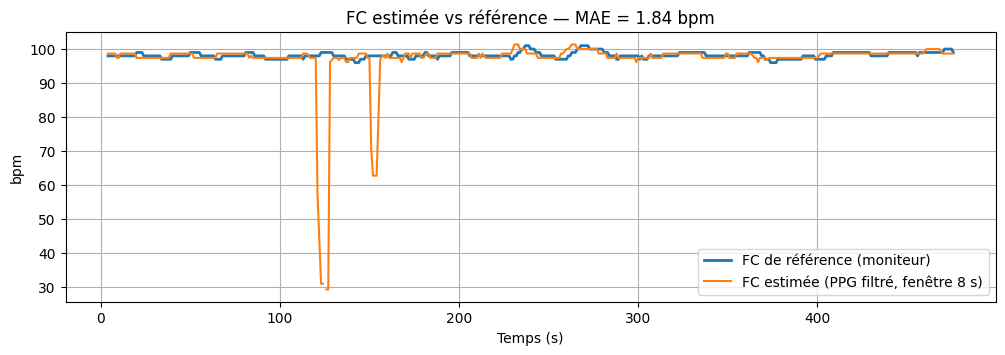

In [8]:
instants, fc_ref = reference_fc(numerics, t)            # une FC de référence par seconde
fc_est, cv_est = fc_par_fenetre(t_pics, instants)        # notre FC par seconde (fenêtre 8 s)
mae_filtre = mae(fc_est, fc_ref)


def estimer_fc(x, filtrer=True):
    """Chaîne complète avec VOS réglages : filtre -> pics -> FC par fenêtre de 8 s."""
    x = signal.sosfiltfilt(sos, x) if filtrer else x - np.mean(x)
    p, _ = signal.find_peaks(x, distance=distance_min, prominence=PROEMINENCE * np.std(x))
    return fc_par_fenetre(t[p], instants)


fc_sans_filtre, _ = estimer_fc(ppg_brut, filtrer=False)
mae_brut = mae(fc_sans_filtre, fc_ref)

print(f"MAE avec filtre {F_BAS}-{F_HAUT} Hz : {mae_filtre:.2f} bpm")
print(f"MAE sans filtre        : {mae_brut:.2f} bpm")

plt.plot(instants, fc_ref, label="FC de référence (moniteur)", lw=2)
plt.plot(instants, fc_est, label="FC estimée (PPG filtré, fenêtre 8 s)")
plt.title(f"FC estimée vs référence — MAE = {mae_filtre:.2f} bpm")
plt.xlabel("Temps (s)")
plt.ylabel("bpm")
plt.legend()
plt.show()

**Question 6.** Notez l'erreur moyenne (MAE) avec et sans filtre. Sur votre patient, le filtre aide-t-il (oui / non) ? Une erreur de cet ordre est-elle acceptable pour un appareil de suivi à domicile ? Pourquoi, en une phrase ?

*Vos réponses :*

| | MAE |
| --- | --- |
| Avec filtre 0,5-5 Hz | **1,84 bpm** |
| Sans filtre | **0,88 bpm** |

**Le filtre aide-t-il ? Oui — malgré ce que le chiffre global laisse croire.** Sur ce patient, la comparaison brute est trompeuse, et il faut regarder où se fait l'erreur :

| Zone | MAE avec filtre | MAE sans filtre |
| --- | --- | --- |
| Hors décrochages capteur (90 % du temps) | **0,74 bpm** | 0,83 bpm |
| Pendant les décrochages (113-136 s et 145-162 s) | 14,03 bpm | 1,51 bpm |
| Couverture (fenêtres où une FC est produite) | 99,8 % | 98,9 % |

Sur le signal exploitable, le filtre fait bien mieux (0,74 contre 0,83 bpm). Pendant les décrochages de l'étape 5, le filtre amplifie le résidu d'un signal plat et fabrique quelques faux pics (4 pics détectés entre 119 et 130 s là où 18 sont attendus) ; la chaîne **sans** filtre, elle, n'y trouve carrément pas assez de pics pour remplir une fenêtre de 8 s, renvoie `NaN` — et ces secondes sont **exclues du calcul de la MAE**. Le signal brut ne gagne donc pas en justesse : il gagne en **refusant de répondre**. C'est un faux ami, et c'est l'argument central de l'étape 8.

**Acceptable pour un suivi à domicile ?** Sur les fenêtres de qualité suffisante, oui : **0,7 bpm** est très en dessous des ±5 bpm (ou ±10 %) tolérés par les cardiofréquencemètres grand public, et sans commune mesure avec les seuils qui déclenchent une alerte (bradycardie < 50, tachycardie > 120 bpm). Mais la moyenne globale de 1,84 bpm **masque** des erreurs de 14 bpm sur 10 % du temps : un appareil qui publierait sa FC en continu afficherait donc des valeurs franchement fausses plusieurs dizaines de secondes par enregistrement. Une MAE moyenne ne suffit pas comme critère produit — il faut une règle de qualité par fenêtre.

## Étape 7 — Simuler un mouvement du patient

Les patients de BIDMC sont allongés et immobiles. À domicile, on bouge. Le notebook ajoute donc un **artefact** : une perturbation qui ne vient pas du cœur. Il imite un bras qui bouge pendant la marche : des secousses de 1 à 3 fois par seconde (**1 à 3 Hz**), plus des sauts brusques du niveau du signal, de 200 à 240 s. `GAIN_ARTEFACT` règle la force du mouvement (0 = pas de mouvement).

✏️ **À vous** :
1. Exécutez avec le gain par défaut (3). Notez l'erreur sur tout l'enregistrement et l'erreur pendant l'artefact.
2. Mettez le gain à 1, relancez, notez les deux mêmes chiffres.
3. **Revenez à 3** : c'est le réglage de la suite et de votre ligne de résultats.

**Vous devez voir** : un signal désordonné dans la zone rouge, et une FC estimée qui s'écarte de la référence dans cette zone.

MAE sur tout l'enregistrement : 2.00 bpm (sans artefact : 1.84 bpm)
MAE pendant l'artefact        : 10.55 bpm (sans artefact, mêmes secondes : 0.90 bpm)
Pire écart pendant l'artefact : 27 bpm


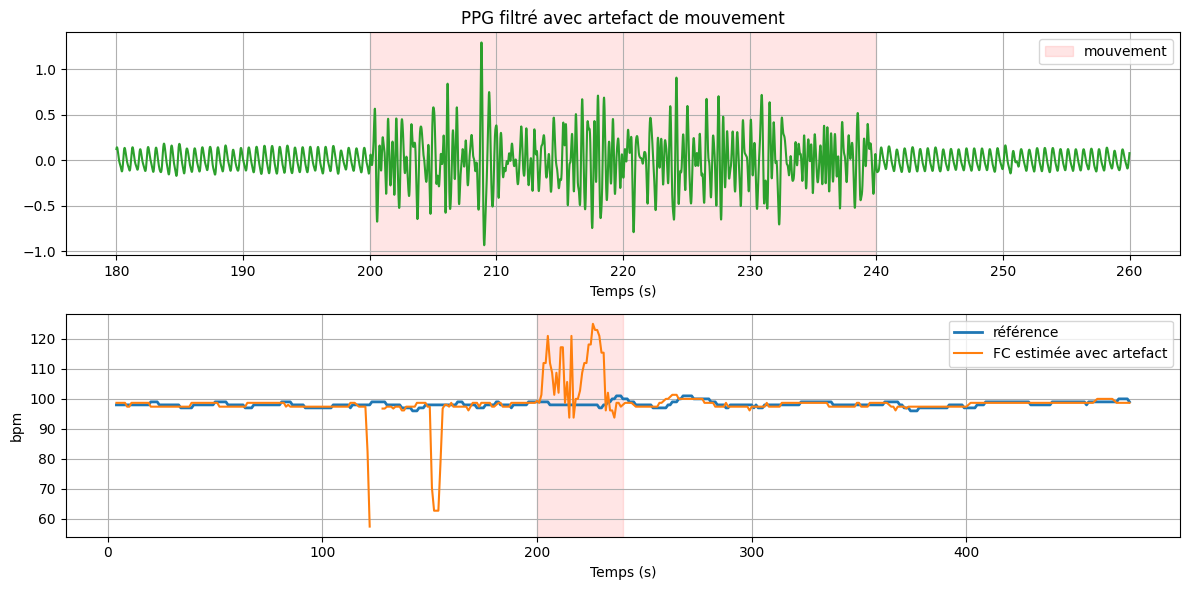

In [9]:
#@title À vous : artefact de mouvement { run: "auto" }
GAIN_ARTEFACT = 3.0  #@param {type:"slider", min:0, max:10, step:0.5}
DEBUT_ARTEFACT = 200  #@param {type:"slider", min:20, max:400, step:10}
DUREE_ARTEFACT = 40  #@param {type:"slider", min:10, max:60, step:10}

ppg_art = ajouter_artefact(ppg_brut, t, DEBUT_ARTEFACT, DUREE_ARTEFACT, GAIN_ARTEFACT)
fc_art, cv_art = estimer_fc(ppg_art)
zone_art = (instants >= DEBUT_ARTEFACT) & (instants < DEBUT_ARTEFACT + DUREE_ARTEFACT)

mae_art = mae(fc_art, fc_ref)
mae_art_zone = mae(fc_art, fc_ref, zone_art)
print(f"MAE sur tout l'enregistrement : {mae_art:.2f} bpm (sans artefact : {mae_filtre:.2f} bpm)")
print(f"MAE pendant l'artefact        : {mae_art_zone:.2f} bpm "
      f"(sans artefact, mêmes secondes : {mae(fc_est, fc_ref, zone_art):.2f} bpm)")
print(f"Pire écart pendant l'artefact : {np.nanmax(np.abs(fc_art - fc_ref)[zone_art]):.0f} bpm")

vue = (t >= DEBUT_ARTEFACT - 20) & (t < DEBUT_ARTEFACT + DUREE_ARTEFACT + 20)
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(t[vue], signal.sosfiltfilt(sos, ppg_art)[vue], color="tab:green")
axes[0].axvspan(DEBUT_ARTEFACT, DEBUT_ARTEFACT + DUREE_ARTEFACT, color="red", alpha=0.1, label="mouvement")
axes[0].set(title="PPG filtré avec artefact de mouvement", xlabel="Temps (s)")
axes[0].legend()
axes[1].plot(instants, fc_ref, label="référence", lw=2)
axes[1].plot(instants, fc_art, label="FC estimée avec artefact")
axes[1].axvspan(DEBUT_ARTEFACT, DEBUT_ARTEFACT + DUREE_ARTEFACT, color="red", alpha=0.1)
axes[1].set(xlabel="Temps (s)", ylabel="bpm")
axes[1].legend()
plt.tight_layout()
plt.show()

**Question 7.** Notez l'erreur moyenne (MAE) pendant l'artefact pour un gain de 3, puis de 1. Pourquoi le filtre 0,5-5 Hz n'enlève-t-il pas ce mouvement ? (Aide : le mouvement va de 1 à 3 Hz.) Pourquoi l'erreur sur tout l'enregistrement augmente-t-elle beaucoup moins ?

*Vos réponses :*

| GAIN_ARTEFACT | MAE pendant l'artefact (200-240 s) | Pire écart | MAE sur tout l'enregistrement |
| --- | --- | --- | --- |
| 3 (retenu) | **10,55 bpm** | **27 bpm** | 2,00 bpm |
| 1 | **6,43 bpm** | 29 bpm | 2,31 bpm |
| *référence : mêmes secondes sans artefact* | *0,90 bpm* | — | *1,84 bpm* |

**Pourquoi le filtre 0,5-5 Hz n'enlève pas le mouvement.** Les secousses simulées vont de **1 à 3 Hz**, c'est-à-dire **60 à 180 bpm** : elles tombent en plein milieu de la bande qu'on a décidé de garder. Un filtre ne sait trier que sur la vitesse de variation ; or ici le mouvement varie exactement à la même vitesse que le pouls. Aucun réglage de `F_BAS` / `F_HAUT` ne peut les séparer — le resserrer détruirait le pouls en même temps (on l'a vu à l'étape 3). Il faut donc un critère **d'une autre nature** : la régularité (étape 8), ou un accéléromètre.

**Pourquoi la MAE globale bouge peu.** L'artefact ne dure que **40 s sur 480**, soit 8 % du temps : une erreur de 10 bpm diluée sur 92 % de signal propre pèse peu dans une moyenne. C'est le défaut classique d'un indicateur moyenné — il noie un épisode grave dans une masse de secondes correctes.

Détail amusant mesuré ici : la MAE **totale** est même plus basse à gain 3 (2,00) qu'à gain 1 (2,31). Ce n'est pas un bug. Le seuil de détection vaut `PROEMINENCE × np.std(signal)` : un artefact fort augmente l'écart-type global, donc relève le seuil partout, ce qui supprime au passage des faux pics dans les zones de décrochage capteur. Autrement dit un seuil **relatif** au signal entier se laisse déplacer par une perturbation locale — à retenir pour l'implémentation ESP32, où il vaudra mieux un seuil adaptatif calculé sur une fenêtre glissante récente.

Réglage conservé pour l'étape 8 et la ligne de résultats : **GAIN_ARTEFACT = 3, de 200 à 240 s**.

## Étape 8 — Une note de confiance et la règle produit

Au repos, les battements sont **réguliers**. Un mouvement crée des « faux battements » espacés au hasard. Pour chaque fenêtre de 8 s, le notebook mesure donc la régularité avec le **CV** (coefficient de variation) : la dispersion des temps entre battements (leur écart-type) divisée par leur moyenne. Exemple : 0,03 ÷ 0,66 ≈ 0,05. Petit CV = battements réguliers.

Une fenêtre est de **qualité suffisante** si le CV est plus petit que `SEUIL_CV` **et** si la FC est entre 40 et 180 bpm.

**Règle produit** : *si la qualité est insuffisante, l'appareil n'envoie pas de FC* ; il envoie « qualité insuffisante ». On suit deux chiffres : la **justesse** des FC envoyées (leur erreur moyenne) et le **taux de transmission** (la part du temps où une FC est envoyée).

✏️ **À vous** :
1. Exécutez avec `SEUIL_CV` = 0,15 et notez les deux chiffres.
2. Testez 0,30 et notez les deux mêmes chiffres.
3. Regardez la ligne **sans artefact** : la FC est-elle envoyée 100 % du temps ?
4. Revenez au seuil que vous retenez.

**Vous devez voir** : la zone du mouvement rejetée (bandes rouges), une erreur des FC envoyées proche de celle sans mouvement, et un taux de transmission inférieur à 100 %.

sans artefact : FC transmise  93.9 % du temps | MAE des FC transmises  0.74 bpm | MAE sans règle  1.84 bpm
avec artefact : FC transmise  84.8 % du temps | MAE des FC transmises  0.72 bpm | MAE sans règle  2.00 bpm
Pendant l'artefact : FC transmise 0 % du temps


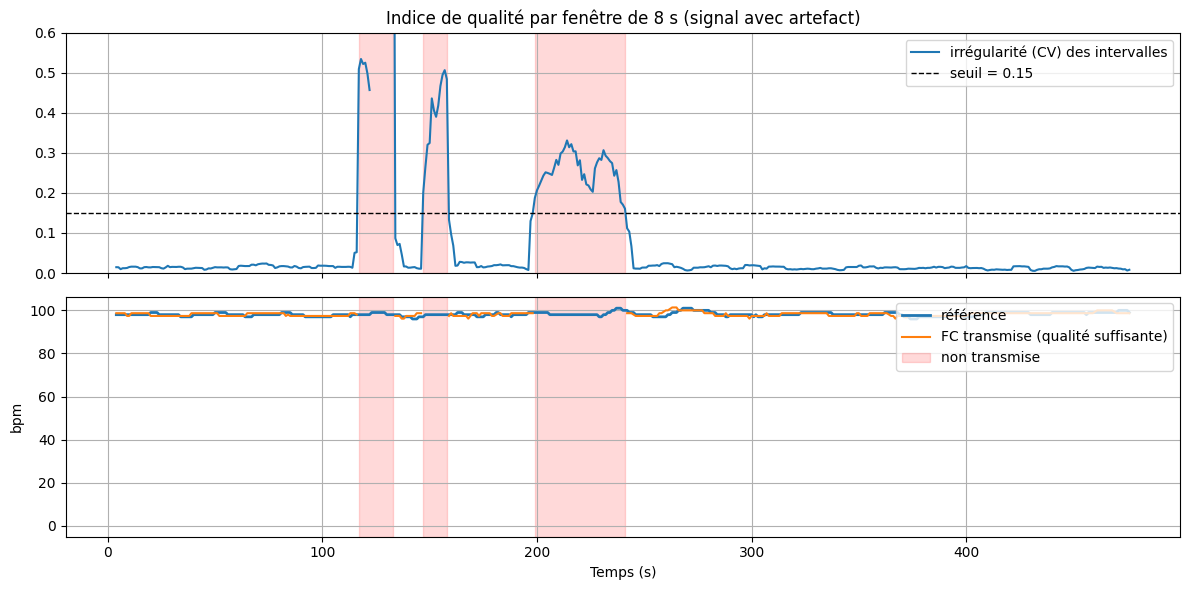

{"t_s": 170, "heart_rate": 99, "hr_quality": "ok"}
{"t_s": 220, "heart_rate": null, "hr_quality": "insuffisante"}
{"t_s": 270, "heart_rate": 100, "hr_quality": "ok"}


In [10]:
#@title À vous : seuil de qualité { run: "auto" }
SEUIL_CV = 0.15  #@param {type:"slider", min:0.02, max:0.5, step:0.01}


def qualite_suffisante(fc, cv):
    """Vrai si la fenêtre est régulière ET la FC plausible."""
    return (cv < SEUIL_CV) & (fc >= 40) & (fc <= 180)   # (les fenêtres vides donnent Faux)


ok_propre = qualite_suffisante(fc_est, cv_est)   # signal d'origine
ok_art = qualite_suffisante(fc_art, cv_art)      # signal avec artefact
fc_transmise = np.where(ok_art, fc_art, np.nan)  # règle produit : rien si qualité insuffisante

for nom, fc, ok in [("sans artefact", fc_est, ok_propre), ("avec artefact", fc_art, ok_art)]:
    print(f"{nom:>13} : FC transmise {100 * ok.mean():5.1f} % du temps | "
          f"MAE des FC transmises {mae(fc, fc_ref, ok):5.2f} bpm | MAE sans règle {mae(fc, fc_ref):5.2f} bpm")
print(f"Pendant l'artefact : FC transmise {100 * ok_art[zone_art].mean():.0f} % du temps")

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(instants, cv_art, label="irrégularité (CV) des intervalles")
axes[0].axhline(SEUIL_CV, color="k", ls="--", lw=1, label=f"seuil = {SEUIL_CV}")
axes[0].set(ylim=(0, 0.6), title="Indice de qualité par fenêtre de 8 s (signal avec artefact)")
axes[0].legend(loc="upper right")
axes[1].plot(instants, fc_ref, label="référence", lw=2)
axes[1].plot(instants, fc_transmise, label="FC transmise (qualité suffisante)")
for ax in axes:
    ax.fill_between(instants, 0, 1, where=~ok_art, color="red", alpha=0.15,
                    transform=ax.get_xaxis_transform(), label="non transmise")
axes[1].set(xlabel="Temps (s)", ylabel="bpm")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

# Ce que le dispositif publierait (clé heart_rate du contrat MQTT du module 1)
for tc in [DEBUT_ARTEFACT - 30, DEBUT_ARTEFACT + DUREE_ARTEFACT / 2, DEBUT_ARTEFACT + DUREE_ARTEFACT + 30]:
    k = int(np.argmin(np.abs(instants - tc)))
    message = {"t_s": int(instants[k]),
               "heart_rate": round(float(fc_art[k])) if ok_art[k] else None,
               "hr_quality": "ok" if ok_art[k] else "insuffisante"}
    print(json.dumps(message))

**Question 8.** En passant de 0,15 à 0,30, que gagnez-vous et que perdez-vous ? Même **sans** artefact, certaines fenêtres sont-elles rejetées (oui / non) ? Si oui, zoomez sur l'une d'elles (étape 2) : est-ce du bruit, ou le cœur qui bat de façon irrégulière ?

**Question 9.** Quand la qualité est insuffisante, que doit afficher l'appareil au patient ? Et au soignant ? Quel risque cette règle crée-t-elle si le cœur du patient bat vraiment de façon irrégulière ? (Une phrase pour chaque.)

*Vos réponses :*

**Question 8.**

| SEUIL_CV | FC transmise | MAE des FC transmises | Transmis pendant l'artefact |
| --- | --- | --- | --- |
| 0,15 (retenu) | **84,8 %** | **0,72 bpm** | **0 %** |
| 0,30 | **92,6 %** | **1,46 bpm** | 80 % |
| *sans règle (rappel)* | 100 % | 2,00 bpm | 100 % |

**En passant de 0,15 à 0,30 : on gagne de la disponibilité, on perd de la justesse.** On gagne 7,8 points de temps de transmission (84,8 → 92,6 %), mais la MAE des valeurs envoyées double (0,72 → 1,46 bpm) : le seuil large laisse passer 80 % des fenêtres de mouvement, c'est-à-dire précisément celles qui sont fausses. C'est le compromis précision / rappel de Digi4, transposé à un produit : *afficher souvent* contre *afficher juste*. Pour un dispositif de suivi, la valeur fausse coûte plus cher que la valeur absente — une FC erronée déclenche une alerte inutile (ou pire, en masque une vraie). **Nous retenons SEUIL_CV = 0,15**, qui ramène la justesse des valeurs envoyées (0,72 bpm) au niveau du signal sans artefact (0,74 bpm) tout en transmettant encore 85 % du temps.

**Même sans artefact, des fenêtres sont-elles rejetées ? Oui.** 29 fenêtres sur 473, soit **6,1 % du temps** : FC transmise 93,9 % au lieu de 100 %. Elles sont groupées en deux blocs, **117-133 s** et **147-158 s** — exactement les instants repérés à l'étape 5.

**Bruit, ou cœur irrégulier ? Du bruit capteur.** Le zoom montre un signal plat par paliers puis saturé (0,0 et 1,0), pas une suite de battements mal espacés. Et la FC du moniteur, issue de l'ECG, reste à 98 bpm pendant tout l'épisode : le rythme cardiaque est régulier, c'est la voie optique qui a décroché. Le CV médian hors de ces zones est de **0,014** (battements très réguliers) contre un maximum de **1,39** pendant le décrochage — le critère sépare donc nettement les deux situations.

---

**Question 9.**

**Au patient :** pas de chiffre, jamais une FC approximative — un message d'état simple et actionnable, du type « Mesure impossible : restez immobile et vérifiez la position du capteur », éventuellement avec la dernière valeur fiable clairement horodatée (« 98 bpm il y a 2 min ») pour ne pas être anxiogène.

**Au soignant :** la même absence de valeur, mais **tracée et explicite** — le dispositif publie `{"t_s": 220, "heart_rate": null, "hr_quality": "insuffisante"}` (clé `heart_rate` du contrat MQTT du module 1), et le tableau de bord affiche la durée du trou et le taux de transmission sur la période. Un silence doit se voir comme un silence, pas comme une ligne plate : le soignant doit pouvoir distinguer « capteur à repositionner » de « résident sans mesure depuis 20 minutes ».

**Le risque de cette règle :** une **vraie arythmie** (fibrillation auriculaire, extrasystoles fréquentes) produit un CV élevé pour la même raison qu'un mouvement — les intervalles entre battements deviennent irréguliers. La règle va donc **censurer précisément l'anomalie qu'on voudrait le plus détecter**, et le dossier du résident montrera un trou de données là où il aurait dû montrer une alerte. Deux garde-fous à prévoir : traiter la **qualité insuffisante persistante** comme un signal en soi (alerte si elle dure plus de X minutes, plutôt qu'un simple blanc), et ajouter un critère capable de distinguer les deux cas — un accéléromètre (y a-t-il eu mouvement ?) ou la ressemblance de forme entre battements, qui reste bonne en arythmie et s'effondre en cas de mouvement.

## Étape 9 — Synthèse de l'équipe

▶ **Exécutez la cellule suivante.** Elle récapitule vos résultats et affiche **une ligne à copier dans le canal de la promo** (comparaison en plénière). Dans le tableau, `NaN` veut dire « pas de valeur » : aucune FC envoyée sur cette période.

In [11]:
synthese = pd.DataFrame({
    "Configuration": ["Sans filtre", f"Filtre {F_BAS}-{F_HAUT} Hz", "Filtre + règle qualité",
                      "Filtre + artefact", "Filtre + artefact + règle qualité"],
    "MAE (bpm)": [mae_brut, mae_filtre, mae(fc_est, fc_ref, ok_propre), mae_art, mae(fc_art, fc_ref, ok_art)],
    "MAE pendant l'artefact (bpm)": [np.nan, mae(fc_est, fc_ref, zone_art), mae(fc_est, fc_ref, zone_art & ok_propre),
                                     mae_art_zone, mae(fc_art, fc_ref, zone_art & ok_art)],
    "FC transmise (% du temps)": [100 * np.mean(~np.isnan(fc_sans_filtre)), 100 * np.mean(~np.isnan(fc_est)),
                                  100 * ok_propre.mean(), 100 * np.mean(~np.isnan(fc_art)), 100 * ok_art.mean()],
}).round(1)

ligne_resultats = (f"Équipe {EQUIPE:02d} | {SOURCE} | FC réf. {numerics['HR'].mean():.0f} bpm | "
                   f"MAE {mae_filtre:.1f} bpm | MAE artefact {mae_art_zone:.1f} bpm | "
                   f"MAE transmise {mae(fc_art, fc_ref, ok_art):.1f} bpm ({100 * ok_art.mean():.0f} % transmis) | "
                   f"réglage {F_BAS}-{F_HAUT} Hz ordre {ORDRE}, FC_MAX {FC_MAX}, seuil CV {SEUIL_CV}")
print(ligne_resultats)
synthese

Équipe 05 | BIDMC enregistrement 05 | FC réf. 98 bpm | MAE 1.8 bpm | MAE artefact 10.5 bpm | MAE transmise 0.7 bpm (85 % transmis) | réglage 0.5-5.0 Hz ordre 4, FC_MAX 180, seuil CV 0.15


,Configuration,MAE (bpm),MAE pendant l'artefact (bpm),FC transmise (% du temps)
0,Sans filtre,0.9,NaN,98.9
1,Filtre 0.5-5.0 Hz,1.8,0.9,99.8
2,Filtre + règle qualité,0.7,0.9,93.9
3,Filtre + artefact,2.0,10.5,98.9
4,Filtre + artefact + règle qualité,0.7,NaN,84.8


### Votre synthèse (5 lignes)

✏️ **À vous** : complétez les 5 lignes de `SYNTHESE` ci-dessous (remplacez les « … »), puis exécutez la cellule. Elle écrit `analyses/m2_tp1/synthese.md` (vos 5 lignes, la ligne de résultats et le tableau) et, dans Colab, le télécharge. Déposez ce fichier et le notebook exécuté dans le repo de l'équipe (voir l'énoncé, section Livrable).

In [12]:
#@title À vous : synthèse de l'équipe (5 lignes)
SYNTHESE = """
1. Enregistrement et source : BIDMC enregistrement 05 (PhysioNet, téléchargement réussi — pas de repli synthétique), 60 001 échantillons à 125 Hz, 480 s ; FC de référence du moniteur 98,2 bpm en moyenne (96 à 101 bpm).
2. Erreur obtenue : MAE 1,84 bpm avec le filtre 0,5-5 Hz contre 0,88 bpm sans filtre — chiffre trompeur : hors des deux décrochages capteur (113-136 s et 145-162 s) le filtre fait mieux (0,74 contre 0,83 bpm), et la chaîne sans filtre ne « gagne » que parce qu'elle ne produit aucune valeur pendant ces décrochages (couverture 98,9 % contre 99,8 %).
3. Effet de l'artefact (gain 3, 200-240 s) : MAE 10,55 bpm pendant l'artefact contre 0,90 bpm sur les mêmes secondes sans artefact, pire écart 27 bpm ; MAE globale seulement 2,00 bpm car l'épisode ne pèse que 8 % du temps. Le filtre ne peut rien : les secousses sont à 1-3 Hz, soit 60-180 bpm, en plein dans la bande du pouls.
4. Effet de la règle qualité (SEUIL_CV = 0,15) : MAE des FC transmises 0,72 bpm (contre 2,00 bpm sans la règle), transmission 84,8 % du temps et 0 % pendant l'artefact — la totalité de la zone de mouvement est rejetée. Même sans artefact, 6,1 % des fenêtres sont rejetées : ce sont les décrochages du capteur, pas une irrégularité cardiaque (la FC ECG du moniteur reste à 98 bpm).
5. Réglage retenu : filtre Butterworth 0,5-5 Hz ordre 4 (couvre 30-300 bpm, coupe la dérive respiratoire et le bruit), FC_MAX 180 bpm avec PROEMINENCE 0,5 (766 battements détectés, contre 337 à FC_MAX 60 et 792 à FC_MAX 300 sans proéminence), SEUIL_CV 0,15 plutôt que 0,30 : à 0,30 on transmettrait 7,8 points de temps en plus mais avec une erreur doublée (1,46 bpm), car 80 % des fenêtres de mouvement passeraient le filtre qualité. Pour un dispositif de suivi, une valeur fausse coûte plus cher qu'une valeur absente.
"""

dossier = Path("analyses/m2_tp1")
dossier.mkdir(parents=True, exist_ok=True)
fichier = dossier / "synthese.md"
fichier.write_text(f"# TP M2-1 — Synthèse de l'équipe {EQUIPE:02d}\n\n{SYNTHESE.strip()}\n\n"
                   f"Résultats : {ligne_resultats}\n\n```\n{synthese.to_string(index=False)}\n```\n",
                   encoding="utf-8")
print(fichier.read_text(encoding="utf-8"))
try:
    from google.colab import files   # dans Colab : téléchargement automatique du fichier
    files.download(str(fichier))
except ImportError:
    print(f"En local : fichier écrit dans {fichier} (dossier du notebook)")

# TP M2-1 — Synthèse de l'équipe 05

1. Enregistrement et source : BIDMC enregistrement 05 (PhysioNet, téléchargement réussi — pas de repli synthétique), 60 001 échantillons à 125 Hz, 480 s ; FC de référence du moniteur 98,2 bpm en moyenne (96 à 101 bpm).
2. Erreur obtenue : MAE 1,84 bpm avec le filtre 0,5-5 Hz contre 0,88 bpm sans filtre — chiffre trompeur : hors des deux décrochages capteur (113-136 s et 145-162 s) le filtre fait mieux (0,74 contre 0,83 bpm), et la chaîne sans filtre ne « gagne » que parce qu'elle ne produit aucune valeur pendant ces décrochages (couverture 98,9 % contre 99,8 %).
3. Effet de l'artefact (gain 3, 200-240 s) : MAE 10,55 bpm pendant l'artefact contre 0,90 bpm sur les mêmes secondes sans artefact, pire écart 27 bpm ; MAE globale seulement 2,00 bpm car l'épisode ne pèse que 8 % du temps. Le filtre ne peut rien : les secousses sont à 1-3 Hz, soit 60-180 bpm, en plein dans la bande du pouls.
4. Effet de la règle qualité (SEUIL_CV = 0,15) : MAE des FC transmi

---
## Référence
Pimentel M.A.F. et al., « Toward a Robust Estimation of Respiratory Rate From Pulse Oximeters », *IEEE Transactions on Biomedical Engineering*, 64(8), 2017. Goldberger A.L. et al., « PhysioBank, PhysioToolkit, and PhysioNet », *Circulation*, 101(23), 2000. Jeu de données : https://physionet.org/content/bidmc/1.0.0/ (DOI 10.13026/C2208R).